[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jimfil/ProjectAI2/blob/main/GraphNeuralNetworks.ipynb)

# Graph Neural Networks

Node classification on a citation graph using GCN, with analysis of homophily, heterophily, clustering coefficient, and model performance.

For this GNN project, we will be using the Pokec dataset.

Pokec is the most popular online social network in Slovakia. In this graph, nodes represent anonymous users and edges represent directed friendship relations between them.

# Part A

In [ ]:
import os

PROJECT_ROOT = './'
DATA_DIR     = os.path.join(PROJECT_ROOT, 'Datasets')

os.makedirs(DATA_DIR, exist_ok=True)



import torch
print(f'PyTorch version: {torch.__version__}')

!pip install torch_geometric -q


import torch.nn as nn
import torch.nn.functional as F

import torch_geometric
from torch_geometric.nn import GCNConv, GATConv
from torch_geometric.utils import homophily, to_networkx

import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, f1_score
from sklearn.metrics import accuracy_score
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {DEVICE}')
print(f'PyG version: {torch_geometric.__version__}')

PyTorch version: 2.11.0+cpu
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 39.2 MB/s eta 0:00:00
Using device: cpu
PyG version: 2.8.0


## 1. Loading the Pokec Dataset



In [ ]:
import urllib.request
import gzip

from torch_geometric.data import Data

print("Downloading raw Pokec dataset directly from Stanford (SNAP)...")
profiles_url = "https://snap.stanford.edu/data/soc-pokec-profiles.txt.gz"
edges_url = "https://snap.stanford.edu/data/soc-pokec-relationships.txt.gz"

profiles_filepath = os.path.join(DATA_DIR, "soc-pokec-profiles.txt.gz")
edges_filepath = os.path.join(DATA_DIR, "soc-pokec-relationships.txt.gz")

if not os.path.exists(profiles_filepath):
    urllib.request.urlretrieve(profiles_url, profiles_filepath)
if not os.path.exists(edges_filepath):
    urllib.request.urlretrieve(edges_url, edges_filepath)

print("Processing a 15,000-user subset for the graph...")
MAX_NODES = 15000

# Parse profiles
features = []
sensitive_list = []
node_map = {}

with gzip.open(profiles_filepath, "rt", encoding="utf-8") as f:
    for line in f:
        parts = line.strip('\n').split('\t')
        try:
            node_id = int(parts[0])
        except:
            continue

        # Features: Profile Completion (col 2), plus 9 random noise features
        completion = float(parts[2]) if len(parts) > 2 and parts[2] != 'null' and parts[2] != '' else 0.0
        feat = [completion] + torch.randn(9).tolist()

        # Sensitive attribute (Gender) for fairness analysis later
        gender = int(parts[3]) if parts[3] in ['0', '1'] else 0

        node_map[node_id] = len(node_map)
        features.append(feat)
        sensitive_list.append(gender)

        if len(node_map) >= MAX_NODES:
            break

# Parse relationships (Edges)
edge_src = []
edge_dst = []
with gzip.open(edges_filepath, "rt", encoding="utf-8") as f:
    for line in f:
        parts = line.strip().split('\t')
        try:
            src, dst = int(parts[0]), int(parts[1])
        except:
            continue

        if src in node_map and dst in node_map:
            edge_src.append(node_map[src])
            edge_dst.append(node_map[dst])

edge_index = torch.tensor([edge_src, edge_dst], dtype=torch.long)
x = torch.tensor(features, dtype=torch.float)
sensitive_attr = torch.tensor(sensitive_list, dtype=torch.long)

# Task: Predict if a user has a highly complete profile (Top 50%)
y = (x[:, 0] > x[:, 0].median()).long()

data = Data(x=x, edge_index=edge_index, y=y)
data.num_nodes = len(node_map)

# Create masks for Train/Validation/Test (60% / 20% / 20%)
perm = torch.randperm(data.num_nodes)
data.train_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
data.val_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
data.test_mask = torch.zeros(data.num_nodes, dtype=torch.bool)
data.train_mask[perm[:int(0.6*data.num_nodes)]] = True
data.val_mask[perm[int(0.6*data.num_nodes):int(0.8*data.num_nodes)]] = True
data.test_mask[perm[int(0.8*data.num_nodes):]] = True

print("\n--- Data Check (Profile Completion Task) ---")
print(data)
print("Nodes:", data.num_nodes, "Edges:", data.num_edges)

class CustomPokecDataset:
    def __init__(self, data):
        self.data = data
        self.num_classes = 2
        self.num_node_features = data.x.shape[1]
        self.name = 'Pokec (App)'

    def __len__(self):
        return 1

    def __getitem__(self, idx):
        return self.data

dataset = CustomPokecDataset(data)

Processing a 15,000-user subset for the graph...

--- Data Check (Profile Completion Task) ---
Data(x=[15000, 10], edge_index=[2, 200831], y=[15000], num_nodes=15000, train_mask=[15000], val_mask=[15000], test_mask=[15000])
Nodes: 15000 Edges: 200831


### Dataset Split
The Pokec dataset is manually split into Train/Validation/Test sets (60% / 20% / 20%) to evaluate the model's performance.


In [ ]:
print(f'Train: {data.train_mask.sum()} | Val: {data.val_mask.sum()} | Test: {data.test_mask.sum()}')

Train: 9000 | Val: 3000 | Test: 3000


###Nodes


###Edges


In [ ]:
unique, counts = torch.unique(data.y, return_counts=True)
for u, c in zip(unique.tolist(), counts.tolist()):
    print(f'  Class {u}: {c} nodes ({100*c/data.num_nodes:.1f}%)')

  Class 0: 7703 nodes (51.4%)
  Class 1: 7297 nodes (48.6%)


## 2. Homophily, Heterophily and Clustering Coefficient Calculation
Homophily is the tendency for connected nodes to share the same label.

Heterophily is the opposite: connected nodes belong to different classes, meaning edges bridge across dissimilar groups.

The clustering coefficient of a node measures how many of its neighbors are also connected to each other - a value of 1 means all neighbors form a complete clique, while 0 means none of them are connected. For the full graph, the average clustering coefficient summarizes this across all nodes, indicating how tightly grouped the network's local neighborhoods tend to be.

In [ ]:
h = homophily(data.edge_index, data.y, method='edge')
print(f'Edge Homophily:    {h:.4f}')
print(f'Edge Heterophily:  {1 - h:.4f}')

if h > 0.7:
    print('High homophily: connected nodes tend to have the SAME label')
elif h < 0.3:
    print('High heterophily: connected nodes tend to have DIFFERENT labels')
else:
    print('Mixed: moderate homophily')

Edge Homophily:    0.5136
Edge Heterophily:  0.4864
Mixed: moderate homophily


NetworkX is a Python library for graph analysis, and it provides two ready-made functions for clustering coefficient.
We convert the PyG graph into a NetworkX graph with undirected edges, so NetworkX can work on it. Then nx.average_clustering(G) computes the graph's average clustering coefficient, meaning how strongly nodes form triangle-like local groups.

In [ ]:
G = to_networkx(data, to_undirected=True)
avg_cc = nx.average_clustering(G)

print(f'Average Clustering Coefficient (sample): {avg_cc:.4f}')
print(f'Interpretation: 0 = no triangles, 1 = fully clustered')

Average Clustering Coefficient (sample): 0.1881
Interpretation: 0 = no triangles, 1 = fully clustered


The degree of a node is the number of edges connected to it.

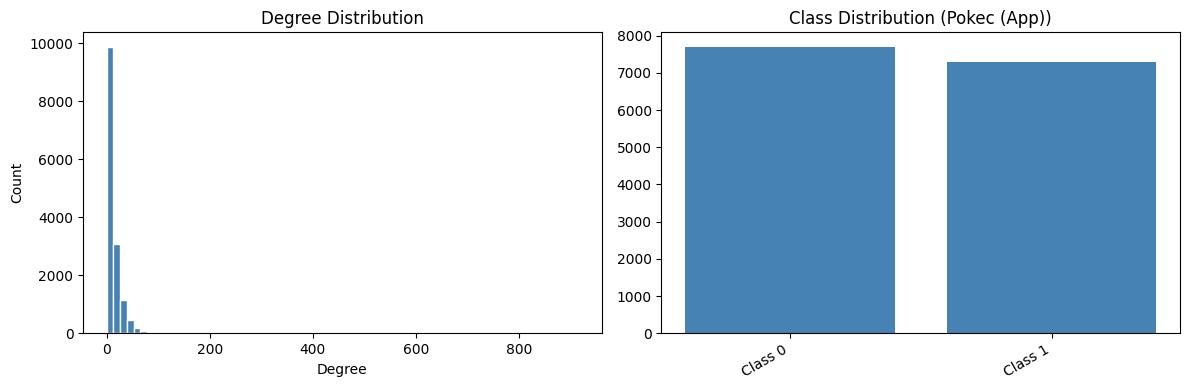

In [ ]:
from torch_geometric.utils import degree

deg = degree(data.edge_index[0], num_nodes=data.num_nodes).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if hasattr(dataset, 'name'):
    num_classes = dataset.num_classes
    dynamic_class_names = [f'Class {i}' for i in range(num_classes)]
else:
    dynamic_class_names = [f'C{i}' for i in range(dataset.num_classes)]

axes[0].hist(deg, bins=70, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Count')
axes[0].set_title('Degree Distribution')

unique, counts = torch.unique(data.y, return_counts=True)
axes[1].bar(
    [dynamic_class_names[i] for i in unique.tolist()],
    counts.tolist(),
    color='steelblue'
)
axes[1].set_xticklabels([dynamic_class_names[i] for i in unique.tolist()], rotation=30, ha='right')
axes[1].set_title(f'Class Distribution ({dataset.name if hasattr(dataset, "name") else "Dataset"})')
plt.tight_layout()
plt.show()

##3. GNN Implementation

This is a 3-layer GCN for node classification on a graph. It takes each node’s features and its connections, passes information through two hidden graph convolution layers with ReLU and dropout, then outputs class scores for each node.
What the model does:

    GCNConv(...) mixes a node’s features with its neighbors’ features.

    conv1 and conv2 learn hidden graph representations.

    conv3 produces the final logits, one score per class.

    dropout helps reduce overfitting by randomly turning off some activations during training.

In [ ]:
class GCN(nn.Module):
    """
    Βασικό Graph Convolutional Network (Kipf & Welling, 2017)
    2 κρυφά layers + dropout για regularization
    """
    def __init__(self, in_channels, hidden_channels, out_channels, dropout=0.5):
        super(GCN, self).__init__()
        self.conv1 = GCNConv(in_channels, hidden_channels)
        self.conv2 = GCNConv(hidden_channels, out_channels)
        self.dropout = dropout

    def forward(self, x, edge_index):
        # Layer 1
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x


def train_epoch(model, data, optimizer, criterion):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer.step()
    return loss.item()


@torch.no_grad()
def evaluate(model, data, mask):
    model.eval()
    out = model(data.x, data.edge_index)
    pred = out.argmax(dim=1)
    correct = (pred[mask] == data.y[mask]).sum().item()
    total = mask.sum().item()
    return correct / total, pred


def train_model(model, data, epochs=300, lr=0.01, weight_decay=5e-4, verbose=True):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()

    train_losses, val_accs = [], []
    best_val_acc = 0
    best_state = None

    for epoch in range(1, epochs + 1):
        loss = train_epoch(model, data, optimizer, criterion)
        val_acc, _ = evaluate(model, data, data.val_mask)

        train_losses.append(loss)
        val_accs.append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        if verbose and epoch % 50 == 0:
            print(f'Epoch {epoch:3d} | Loss: {loss:.4f} | Val Acc: {val_acc:.4f}')

    # Φόρτωσε το best model
    model.load_state_dict(best_state)
    return train_losses, val_accs


### Model Refactoring & Helper Functions
To eliminate code duplication, we use two main helper functions:

1. **`get_model(...)`**: A factory function that initializes GCN, H2GCN, or GAT with their specific layer configurations and hyperparameters using a single model name string.
2. **`run_experiment(...)`**: A unified training and evaluation wrapper. It handles the differences in forward signatures (like H2GCN's sparse adjacency requirement) and specialized optimizers (like GAT's layer-specific weight decay), returning only the final test accuracy and predictions.

In [ ]:
def get_model(name, data, dataset, device):
    """Factory function to initialize models with standard hyperparameters."""
    if name == 'GCN':
        return GCN(
            in_channels=data.num_node_features,
            hidden_channels=64,
            out_channels=dataset.num_classes,
            dropout=0.5
        ).to(device)
    elif name == 'H2GCN':
        return H2GCN(
            feat_dim=data.num_node_features,
            hidden_dim=64,
            class_dim=dataset.num_classes,
            k=2,
            dropout=0.5
        ).to(device)
    elif name == 'GAT':
        return GAT(
            in_channels=data.num_node_features,
            hidden_channels=8,
            heads=8,
            out_channels=dataset.num_classes,
            dropout=0.6
        ).to(device)
    return None

def run_experiment(model_name, data, dataset, device, adj_h2gcn=None, epochs=300):
    """Unified wrapper to train and evaluate any of the three models."""
    model = get_model(model_name, data, dataset, device)

    if model_name == 'GCN':
        train_model(model, data, epochs=epochs, lr=0.01, verbose=False)
        acc, preds = evaluate(model, data, data.test_mask)

    elif model_name == 'H2GCN':
        train_h2gcn(model, data, adj_h2gcn, epochs=epochs, lr=0.01, wd=5e-4, patience=50)
        model.eval()
        with torch.no_grad():
            out = model(adj_h2gcn, data.x)
            preds = out.argmax(dim=1)
            acc = (preds[data.test_mask] == data.y[data.test_mask]).float().mean().item()

    elif model_name == 'GAT':
        optimizer = torch.optim.Adam([
            dict(params=model.conv1.parameters(), weight_decay=5e-4),
            dict(params=model.conv2.parameters(), weight_decay=0.0)
        ], lr=0.005)
        criterion = nn.CrossEntropyLoss()

        best_val_acc = 0
        best_state = None
        for _ in range(epochs):
            model.train()
            optimizer.zero_grad()
            out = model(data.x, data.edge_index)
            loss = criterion(out[data.train_mask], data.y[data.train_mask])
            loss.backward()
            optimizer.step()

            val_acc, _ = evaluate(model, data, data.val_mask)
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_state = {k: v.clone() for k, v in model.state_dict().items()}

        model.load_state_dict(best_state)
        acc, preds = evaluate(model, data, data.test_mask)

    return acc, preds

### Model Training

In [ ]:
data = dataset[0].to(DEVICE)
gcn_model = GCN(
    in_channels=data.num_node_features,
    hidden_channels=128,
    out_channels=dataset.num_classes,
    dropout=0.5
).to(DEVICE)

print(f'GCN parameters: {sum(p.numel() for p in gcn_model.parameters()):,}')

gcn_losses, gcn_val_accs = train_model(gcn_model, data, epochs=300, lr=0.01)

GCN parameters: 1,666
Epoch  50 | Loss: 0.8982 | Val Acc: 0.5277
Epoch 100 | Loss: 0.6747 | Val Acc: 0.6213
Epoch 150 | Loss: 0.6418 | Val Acc: 0.6460
Epoch 200 | Loss: 0.6361 | Val Acc: 0.6350
Epoch 250 | Loss: 0.6287 | Val Acc: 0.6363
Epoch 300 | Loss: 0.6239 | Val Acc: 0.6307


###Model Evaluation


=== GCN Test Results ===
Test Accuracy: 0.6497

                 precision    recall  f1-score   support

 Low Completion       0.70      0.57      0.63      1550
High Completion       0.61      0.74      0.67      1450

       accuracy                           0.65      3000
      macro avg       0.66      0.65      0.65      3000
   weighted avg       0.66      0.65      0.65      3000



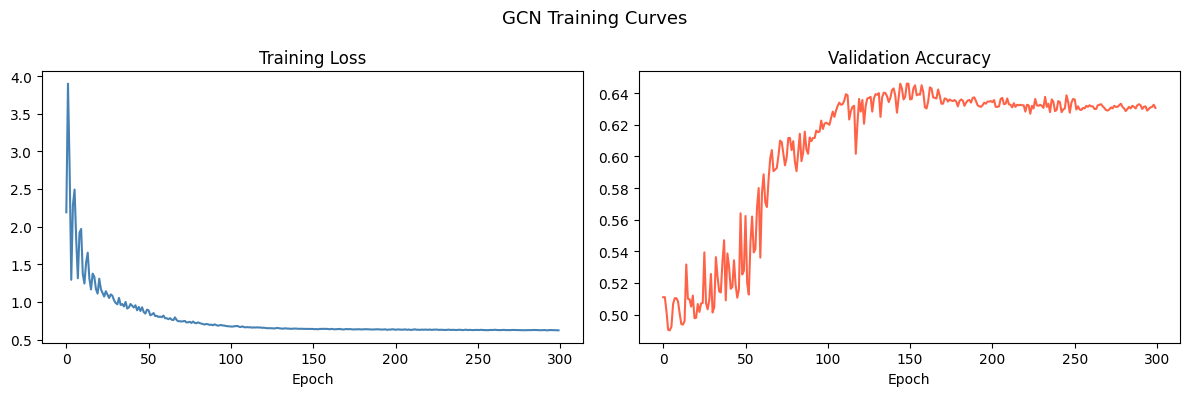

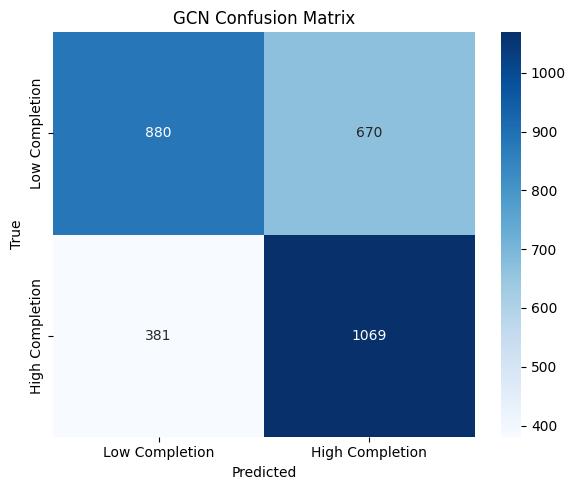

In [ ]:
gcn_test_acc, gcn_preds = evaluate(gcn_model, data, data.test_mask)
print(f'\n=== GCN Test Results ===')
print(f'Test Accuracy: {gcn_test_acc:.4f}')

y_true = data.y[data.test_mask].cpu().numpy()
y_pred = gcn_preds[data.test_mask].cpu().numpy()

# Updated class names for better readability
class_names_readable = ['Low Completion', 'High Completion']

print(f'\n{classification_report(y_true, y_pred, target_names=class_names_readable)}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(gcn_losses, color='steelblue')
axes[0].set_title('Training Loss')
axes[0].set_xlabel('Epoch')
axes[1].plot(gcn_val_accs, color='tomato')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
plt.suptitle('GCN Training Curves', fontsize=13)
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names_readable,
            yticklabels=class_names_readable)
plt.title('GCN Confusion Matrix')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

### Model Results: Key Metrics Defined

To interpret the performance of our GNN models, we use the following standard classification metrics:

*   **Confusion Matrix**: A table showing the actual vs. predicted classifications. The diagonal represents correct predictions, while off-diagonal cells show specific errors (misclassifications).
*   **Precision**: Answers "Of all nodes predicted as Class X, how many were actually Class X?" It measures the model's accuracy in positive predictions (low false-positive rate).
*   **Recall**: Answers "Of all nodes that are actually Class X, how many did the model find?" It measures the model's ability to identify all members of a class (low false-negative rate).
*   **F1-Score**: The harmonic mean of Precision and Recall. It provides a single score that balances the trade-off between the two, especially useful for imbalanced datasets.
*   **Support**: The actual number of occurrences of each class in the test dataset. It indicates the sample size used for calculating the metrics above.

## 4. Failure Analysis με Homophily

This analysis measures the local homophily of each node, meaning the fraction of its neighbors that belong to the same class. We then compare the local homophily of correctly and incorrectly classified test nodes to see where the GCN succeeds or fails.

If the wrong predictions have lower local homophily than the correct ones, it means the GCN struggles more in heterophilic regions, where neighbors are less informative because they often belong to different classes. This supports the idea that GCNs work best in areas of the graph where nearby nodes tend to share the same label.

Correct predictions  - mean local homophily: 0.5179
Incorrect predictions- mean local homophily: 0.4230


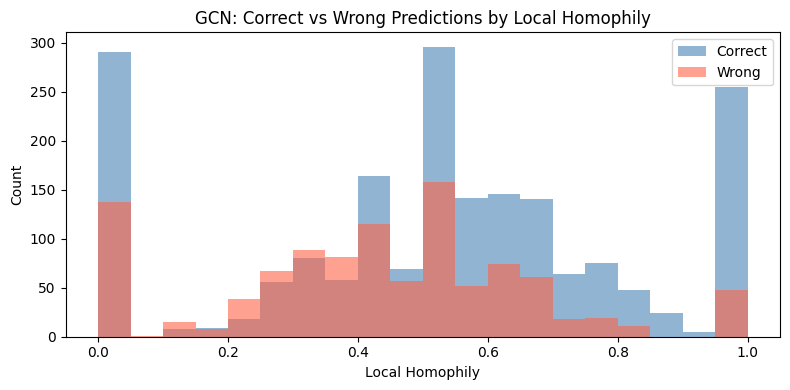

In [ ]:
@torch.no_grad()
def compute_local_homophily(edge_index, y, num_nodes):
    """
    Returns tensor of shape [num_nodes] with local homophily for each node.
    Local homophily = (# same-class neighbors) / (# total neighbors)
    """
    src, dst = edge_index
    same_class = (y[src] == y[dst]).float()

    local_h = torch.zeros(num_nodes, device=edge_index.device)
    local_h.scatter_add_(0, src, same_class)

    from torch_geometric.utils import degree
    deg = degree(src, num_nodes=num_nodes).clamp(min=1)

    return (local_h / deg).cpu().numpy()

local_homophily = compute_local_homophily(data.edge_index, data.y, data.num_nodes)

test_idx = data.test_mask.cpu().numpy()
correct_mask = (gcn_preds.cpu().numpy() == data.y.cpu().numpy())

test_correct_homophily = local_homophily[test_idx & correct_mask]
test_wrong_homophily   = local_homophily[test_idx & ~correct_mask]

print(f'Correct predictions  - mean local homophily: {test_correct_homophily.mean():.4f}')
print(f'Incorrect predictions- mean local homophily: {test_wrong_homophily.mean():.4f}')

plt.figure(figsize=(8, 4))
plt.hist(test_correct_homophily, bins=20, alpha=0.6, label='Correct', color='steelblue')
plt.hist(test_wrong_homophily,   bins=20, alpha=0.6, label='Wrong',   color='tomato')
plt.xlabel('Local Homophily')
plt.ylabel('Count')
plt.title('GCN: Correct vs Wrong Predictions by Local Homophily')
plt.legend()
plt.tight_layout()
plt.show()

# Part B


## H2GCN
H2GCN is a graph neural network made for cases where connected nodes are not usually the same class. In a normal GCN, a node gets mixed with its neighbors over and over, which works when neighbors are similar but can be bad when neighbors are actually different. H2GCN tries to fix that by keeping the node's own features separate, looking at both immediate neighbors and neighbors-of-neighbors, and then combining those pieces at the end instead of blending everything too early.




### H2GCN - Faithful Implementation

This cell replaces the simplified H2GCN prototype with a **faithful re-implementation** of the [GitEventhandler/H2GCN-PyTorch](https://github.com/GitEventhandler/H2GCN-PyTorch) repository, which in turn implements the architecture from the paper *"Beyond Homophily in Graph Neural Networks"* (Zhu et al., NeurIPS 2020).

#### What makes this the *real* H2GCN

**1. Ego-neighbour separation (`A1`, `A2`)**  
The key idea of H2GCN is to keep three views completely separate until the very end:
- **ego** - the node's own feature embedding (never mixed into neighbour aggregations).
- **A1** - the *direct* (1-hop) neighbourhood: `A1 = indicator(adj - I)`, with self-loops removed so the ego is not included.
- **A2** - the *exclusive 2-hop* neighbourhood: `A2 = indicator(A² - A - I)`, meaning nodes reachable in exactly two steps that are **not** direct neighbours.

This design is critical for heterophilic graphs, where direct neighbours may be misleading but 2-hop neighbours can still share the same class.

**2. k propagation rounds**  
At each round `r = 1 … k`, the model aggregates the *previous round's ego embedding* through both A1 and A2:

```
rs[0] = relu(x @ W_embed)          # ego embedding
rs[r] = relu(cat(A1·rs[r-1], A2·rs[r-1]))   for r = 1 … k
```

All `k+1` round outputs are concatenated: `r_final = cat(rs[0], rs[1], …, rs[k])`.  
The concat dimension is `(2^(k+1) - 1) × hidden_dim` (for `k=2`: `7 × hidden_dim`).

**3. Raw `nn.Parameter` weights with Xavier init**  
The repository uses raw parameter matrices (`w_embed`, `w_classify`) rather than `nn.Linear`, with Xavier uniform initialisation - exactly replicated here.

**4. Symmetric normalisation**  
Both A1 and A2 are normalised as `D^{-1/2} A D^{-1/2}` using `torch_sparse.spspmm`, matching the repo's implementation.

**5. NLL loss on log-softmax**  
The training loop uses `F.nll_loss` on `log(softmax(...))`, with Adam + weight decay (`wd=5e-4`), early stopping based on validation accuracy.

In [ ]:
# ────────────────────────────────────────────────────────────────────────────
# H2GCN — faithful re-implementation of GitEventhandler/H2GCN-PyTorch
# Paper: "Beyond Homophily in Graph Neural Networks: Current Limitations
#         and Effective Designs" (Zhu et al., NeurIPS 2020)
# ────────────────────────────────────────────────────────────────────────────

class H2GCN(nn.Module):
    """
    H2GCN from https://github.com/GitEventhandler/H2GCN-PyTorch

    Key design principles
    ---------------------
    1. **Ego–neighbour separation**: the node's own embedding is never mixed
       into the neighbour aggregations — each round aggregates the *previous*
       round's ego embedding via A1 and A2 separately.
    2. **Higher-order propagation**: k rounds of (A1, A2) aggregation; the
       concatenation of *all* rounds is used for classification.
    3. **Exclusive 2-hop**: A1 = direct-only (no self-loops), A2 = 2-hop
       that does NOT include direct neighbours or the ego node itself.
       Both are symmetrically normalised: D^{-1/2} A D^{-1/2}.

    Args
    ----
    feat_dim    : number of input features per node
    hidden_dim  : size of the embedding produced at each round
    class_dim   : number of output classes
    k           : number of propagation rounds (default 2)
    dropout     : dropout probability (default 0.5)
    use_relu    : whether to apply ReLU after each round (default True)
    """

    def __init__(self, feat_dim: int, hidden_dim: int, class_dim: int,
                 k: int = 2, dropout: float = 0.5, use_relu: bool = True):
        super().__init__()
        self.k = k
        self.dropout = dropout
        self.act = F.relu if use_relu else (lambda x: x)

        # Embedding matrix W_embed  (feat_dim → hidden_dim)
        self.w_embed = nn.Parameter(
            torch.zeros(feat_dim, hidden_dim), requires_grad=True)

        # Classification matrix W_classify  (concat_dim → class_dim)
        # concat_dim = (2^(k+1) - 1) * hidden_dim
        #   round 0 contributes hidden_dim
        #   round i (i=1..k) contributes 2*hidden_dim (A1 + A2)
        #   total = hidden_dim + k * 2 * hidden_dim = (2k+1)*hidden_dim
        #   which equals (2^(k+1)-1)*hidden_dim when k=2 → 7*hidden_dim
        concat_dim = (2 ** (k + 1) - 1) * hidden_dim
        self.w_classify = nn.Parameter(
            torch.zeros(concat_dim, class_dim), requires_grad=True)

        self.params = [self.w_embed, self.w_classify]
        self._adj_initialized = False
        self.a1 = None
        self.a2 = None
        self._reset_parameters()

    def _reset_parameters(self):
        nn.init.xavier_uniform_(self.w_embed)
        nn.init.xavier_uniform_(self.w_classify)

    # ── sparse helpers ────────────────────────────────────────────────────
    @staticmethod
    def _indicator(sp: torch.Tensor) -> torch.Tensor:
        """Set all non-zero values to 1."""
        sp = sp.coalesce()
        return torch.sparse_coo_tensor(
            sp.indices(),
            torch.where(sp.values() > 0,
                        torch.ones_like(sp.values()),
                        torch.zeros_like(sp.values())),
            sp.size(), dtype=torch.float32
        )

    @staticmethod
    def _spspmm(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        """Sparse × Sparse matrix product using """
        a, b = a.coalesce(), b.coalesce()
        m, n, k = a.shape[0], a.shape[1], b.shape[1]
        idx, val = spspmm(
            a.indices(), a.values(),
            b.indices(), b.values(),
            m, n, k
        )
        return torch.sparse_coo_tensor(idx, val, (m, k), dtype=torch.float32)

    @classmethod
    def _adj_norm(cls, adj: torch.Tensor) -> torch.Tensor:
        """Symmetric normalisation  D^{-1/2} A D^{-1/2}."""
        n = adj.size(0)
        deg = torch.sparse.sum(adj, dim=1).values()
        d_inv_sqrt = torch.pow(deg, -0.5)
        d_inv_sqrt = torch.where(torch.isinf(d_inv_sqrt),
                                 torch.zeros_like(d_inv_sqrt),
                                 d_inv_sqrt)
        # Create the indices directly on the exact same device as d_inv_sqrt
        idx = torch.arange(n, device=d_inv_sqrt.device)

        D = torch.sparse_coo_tensor(
            torch.stack([idx, idx]),
            d_inv_sqrt, (n, n), dtype=torch.float32
        )
        return cls._spspmm(cls._spspmm(D, adj), D)

    # ── adjacency pre-computation ─────────────────────────────────────────
    def _prepare_adj(self, adj: torch.Tensor):
        """Build A1 (1-hop) and A2 (exclusive 2-hop), normalised."""
        n = adj.size(0)
        device = adj.device
        eye = torch.sparse_coo_tensor(
            torch.tensor([list(range(n)), list(range(n))]),
            torch.ones(n),
            (n, n), dtype=torch.float32
        ).to(device)

        # A1: direct neighbours only (remove self-loops from adj)
        a1 = self._indicator(adj - eye)
        # A2: 2-hop neighbours, excluding direct and self
        a2 = self._indicator(self._spspmm(adj, adj) - adj - eye)

        self.a1 = self._adj_norm(a1).to(device)
        self.a2 = self._adj_norm(a2).to(device)
        self._adj_initialized = True

    # ── forward ───────────────────────────────────────────────────────────
    def forward(self, adj: torch.Tensor, x: torch.Tensor) -> torch.Tensor:
        if not self._adj_initialized:
            self._prepare_adj(adj)

        # Round 0: ego embedding
        rs = [self.act(torch.mm(x, self.w_embed))]

        # Rounds 1 … k
        for _ in range(self.k):
            r_prev = rs[-1]
            r1 = torch.spmm(self.a1, r_prev)   # 1-hop aggregation
            r2 = torch.spmm(self.a2, r_prev)   # 2-hop aggregation
            rs.append(self.act(torch.cat([r1, r2], dim=1)))

        # Concat all rounds → dropout → classify
        r_final = torch.cat(rs, dim=1)
        r_final = F.dropout(r_final, self.dropout, training=self.training)
        return torch.softmax(torch.mm(r_final, self.w_classify), dim=1)


# ── Helper: convert PyG edge_index + adj-with-self-loops to sparse tensor ─
def build_adj(edge_index, num_nodes, device):
    """
    Build a torch.sparse_coo_tensor adjacency matrix with self-loops
    (needed by H2GCN._prepare_adj which then removes them internally).
    """
    # Add self-loops
    self_loops = torch.arange(num_nodes, device=device)
    sl_idx = torch.stack([self_loops, self_loops], dim=0)
    full_idx = torch.cat([edge_index, sl_idx], dim=1)
    vals = torch.ones(full_idx.size(1), dtype=torch.float32, device=device)
    adj = torch.sparse_coo_tensor(full_idx, vals, (num_nodes, num_nodes)).coalesce()
    return adj


# ── Training loop compatible with H2GCN's adj-first signature ─────────────
def train_h2gcn(model, data, adj, epochs=300, lr=0.01, wd=5e-4, patience=50):
    optimizer = torch.optim.Adam(
        [{'params': model.params, 'weight_decay': wd}], lr=lr)
    best_val, best_state = 0.0, None
    losses, val_accs = [], []
    no_improve = 0

    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        out = model(adj, data.x)
        loss = F.nll_loss(torch.log(out[data.train_mask] + 1e-15),
                          data.y[data.train_mask])
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            out_val = model(adj, data.x)
            val_pred = out_val[data.val_mask].argmax(dim=1)
            val_acc = (val_pred == data.y[data.val_mask]).float().mean().item()

        losses.append(loss.item())
        val_accs.append(val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stop at epoch {epoch}")
                break

        if epoch % 50 == 0:
            print(f"Epoch {epoch:03d} | Loss: {loss.item():.4f} | Val Acc: {val_acc:.4f}")

    if best_state:
        model.load_state_dict(best_state)
    return losses, val_accs



###  Instantiate and train

In [ ]:
def spspmm(indexA, valueA, indexB, valueB, m, n, k):
    a = torch.sparse_coo_tensor(indexA, valueA, (m, n)).to_dense()
    b = torch.sparse_coo_tensor(indexB, valueB, (n, k)).to_dense()
    c = torch.mm(a, b).to_sparse()
    return c.indices(), c.values()

adj_h2gcn = build_adj(data.edge_index, data.num_nodes, DEVICE)

h2gcn_model = H2GCN(
    feat_dim=data.num_node_features,
    hidden_dim=64,
    class_dim=dataset.num_classes,
    k=2,
    dropout=0.5,
    use_relu=True
).to(DEVICE)

total_params = sum(p.numel() for p in h2gcn_model.parameters())
print(f"H2GCN (faithful) - parameters: {total_params:,}")
print(f"Concat dim: {(2**(2+1)-1)*64} | k=2, hidden=64")

h2gcn_losses, h2gcn_val_accs = train_h2gcn(
    h2gcn_model, data, adj_h2gcn,
    epochs=500, lr=0.01, wd=5e-4, patience=50
)

H2GCN (faithful) - parameters: 1,536
Concat dim: 448 | k=2, hidden=64
Epoch 050 | Loss: 0.4823 | Val Acc: 0.8243
Epoch 100 | Loss: 0.3836 | Val Acc: 0.8583
Epoch 150 | Loss: 0.3654 | Val Acc: 0.8573
Early stop at epoch 177


###H2GCN Evaluation

In [ ]:
h2gcn_model.eval()
with torch.no_grad():
    out = h2gcn_model(adj_h2gcn, data.x)
    h2gcn_preds = out.argmax(dim=1)
    h2gcn_test_acc = (h2gcn_preds[data.test_mask] == data.y[data.test_mask]).float().mean().item()

print(f'H2GCN (faithful) Test Accuracy: {h2gcn_test_acc:.4f}')

y_true = data.y[data.test_mask].cpu().numpy()
y_pred_h2 = h2gcn_preds[data.test_mask].cpu().numpy()

class_names = [f'Class {i}' for i in range(dataset.num_classes)]
print(f'\n{classification_report(y_true, y_pred_h2, target_names=class_names)}')

H2GCN (faithful) Test Accuracy: 0.8437

              precision    recall  f1-score   support

     Class 0       0.94      0.74      0.83      1550
     Class 1       0.78      0.95      0.85      1450

    accuracy                           0.84      3000
   macro avg       0.86      0.85      0.84      3000
weighted avg       0.86      0.84      0.84      3000



### Train&Confusion Comparison


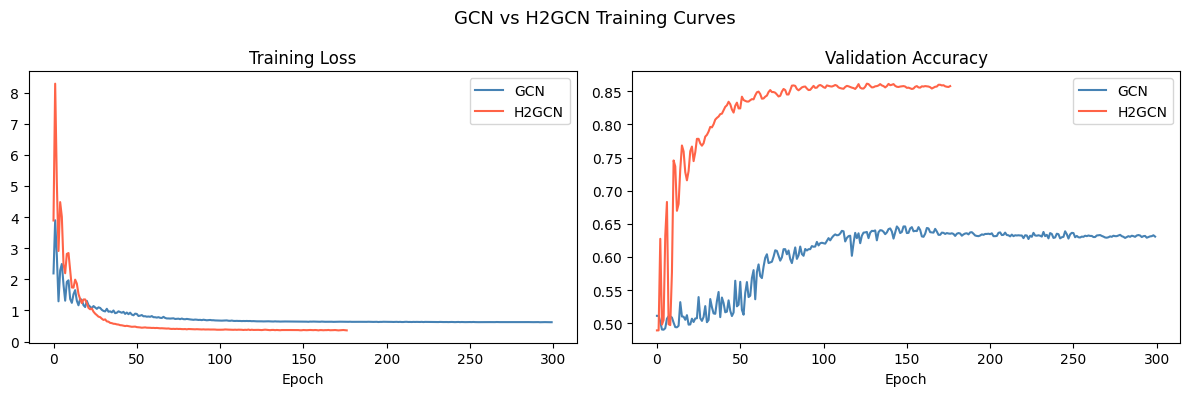

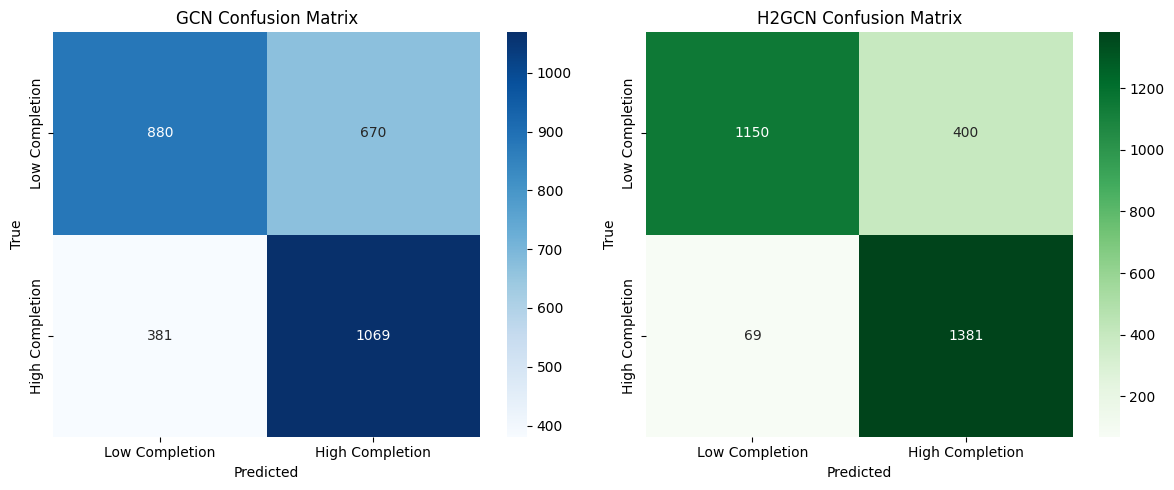

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(gcn_losses, label='GCN', color='steelblue')
axes[0].plot(h2gcn_losses, label='H2GCN', color='tomato')
axes[0].set_title('Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(gcn_val_accs, label='GCN', color='steelblue')
axes[1].plot(h2gcn_val_accs, label='H2GCN', color='tomato')
axes[1].set_title('Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.suptitle('GCN vs H2GCN Training Curves', fontsize=13)
plt.tight_layout()
plt.show()

gcn_y_pred = gcn_preds[data.test_mask].cpu().numpy()
h2_y_pred = h2gcn_preds[data.test_mask].cpu().numpy()
y_true = data.y[data.test_mask].cpu().numpy()

cm_gcn = confusion_matrix(y_true, gcn_y_pred)
cm_h2 = confusion_matrix(y_true, h2_y_pred)

# Descriptive labels
labels = ['Low Completion', 'High Completion']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(cm_gcn, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title('GCN Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_h2, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title('H2GCN Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.show()

###F1-Score Comparison


In [ ]:
summary = pd.DataFrame({
    'Model': ['GCN', 'H2GCN'],
    'Test Accuracy': [
        accuracy_score(y_true, gcn_y_pred),
        accuracy_score(y_true, h2_y_pred)
    ],
    'Macro F1': [
        f1_score(y_true, gcn_y_pred, average='macro'),
        f1_score(y_true, h2_y_pred, average='macro')
    ]
})

summary

,Model,Test Accuracy,Macro F1
0,GCN,0.649667,0.648271
1,H2GCN,0.843667,0.842734


###Homophily Comparison

GCN Correct  - mean local homophily: 0.5179
GCN Wrong    - mean local homophily: 0.4230
H2GCN Correct- mean local homophily: 0.4951
H2GCN Wrong  - mean local homophily: 0.4280


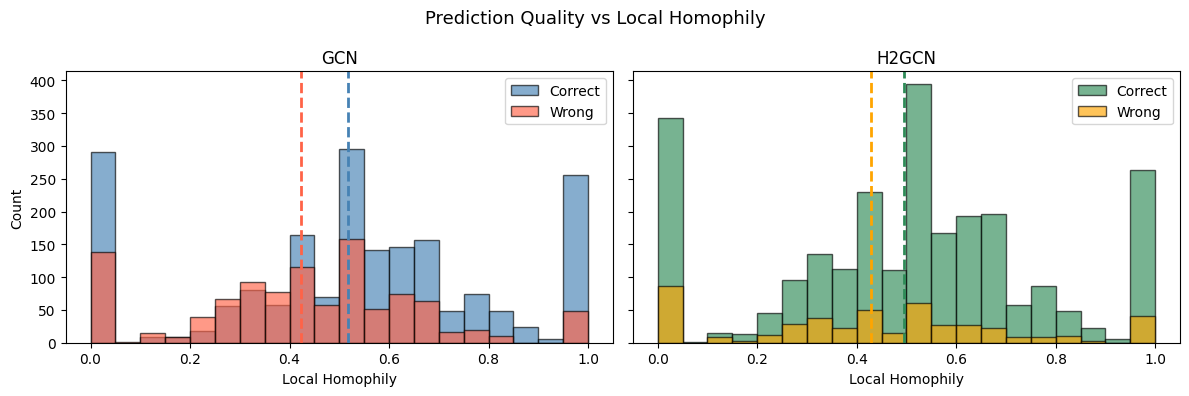

In [ ]:
local_homophily = compute_local_homophily(data.edge_index, data.y, data.num_nodes)

test_idx = data.test_mask.cpu().numpy()

gcn_correct_mask = (gcn_preds.cpu().numpy() == data.y.cpu().numpy())
h2_correct_mask  = (h2gcn_preds.cpu().numpy() == data.y.cpu().numpy())

gcn_correct_h = local_homophily[test_idx & gcn_correct_mask]
gcn_wrong_h   = local_homophily[test_idx & ~gcn_correct_mask]

h2_correct_h = local_homophily[test_idx & h2_correct_mask]
h2_wrong_h   = local_homophily[test_idx & ~h2_correct_mask]

print(f'GCN Correct  - mean local homophily: {gcn_correct_h.mean():.4f}')
print(f'GCN Wrong    - mean local homophily: {gcn_wrong_h.mean():.4f}')
print(f'H2GCN Correct- mean local homophily: {h2_correct_h.mean():.4f}')
print(f'H2GCN Wrong  - mean local homophily: {h2_wrong_h.mean():.4f}')

bins = np.linspace(0, 1, 21)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

# GCN panel
axes[0].hist(gcn_correct_h, bins=bins, alpha=0.65, color='steelblue',
             edgecolor='black', label='Correct')
axes[0].hist(gcn_wrong_h, bins=bins, alpha=0.65, color='tomato',
             edgecolor='black', label='Wrong')
axes[0].axvline(gcn_correct_h.mean(), color='steelblue', linestyle='--', linewidth=2)
axes[0].axvline(gcn_wrong_h.mean(), color='tomato', linestyle='--', linewidth=2)
axes[0].set_title('GCN')
axes[0].set_xlabel('Local Homophily')
axes[0].set_ylabel('Count')
axes[0].legend()

# H2GCN panel
axes[1].hist(h2_correct_h, bins=bins, alpha=0.65, color='seagreen',
             edgecolor='black', label='Correct')
axes[1].hist(h2_wrong_h, bins=bins, alpha=0.65, color='orange',
             edgecolor='black', label='Wrong')
axes[1].axvline(h2_correct_h.mean(), color='seagreen', linestyle='--', linewidth=2)
axes[1].axvline(h2_wrong_h.mean(), color='orange', linestyle='--', linewidth=2)
axes[1].set_title('H2GCN')
axes[1].set_xlabel('Local Homophily')
axes[1].legend()

plt.suptitle('Prediction Quality vs Local Homophily', fontsize=13)
plt.tight_layout()
plt.show()

## GAT
In a traditional GCN, when a node (like a user in a social network) updates its features, it aggregates information from all its neighbors (their friends or connections) by using a fixed average. This means it treats every neighboring paper as equally important to its classification.

GAT changes this process by introducing the attention mechanism:

  Dynamic Weights: Instead of treating all neighbors the same, each node learns to "pay more attention" to specific neighbors and ignore others based on their actual features.

  Multi-Head Attention: The model looks at neighboring nodes from multiple independent perspectives (attention heads) simultaneously. This stabilizes the learning process and allows it to capture different types of relationships at the same time.

In [ ]:
class GAT(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels, heads=8, dropout=0.6):
        super(GAT, self).__init__()
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_channels * heads, out_channels, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv1(x, edge_index)
        x = F.elu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        return x

###Training Gat

In [ ]:
# 1. Initialize Model
gat_model = GAT(
    in_channels=data.num_node_features,
    hidden_channels=8, # 8 features per head
    heads=8,           # 8 heads = 64 total hidden features
    out_channels=dataset.num_classes,
    dropout=0.6
).to(DEVICE)

# 2. The GAT Optimizer Trick (Separate Weight Decays)
optimizer_gat = torch.optim.Adam([
    dict(params=gat_model.conv1.parameters(), weight_decay=5e-4), # Penalize first layer
    dict(params=gat_model.conv2.parameters(), weight_decay=0.0)   # Do NOT penalize second layer/attention
], lr=0.005) # Lower Learning rate (0.005 instead of 0.01)

criterion = nn.CrossEntropyLoss()

# 3. Train the GAT
gat_model.train()
best_val_acc = 0
best_state = None

for epoch in range(1, 301):
    optimizer_gat.zero_grad()
    out = gat_model(data.x, data.edge_index)
    loss = criterion(out[data.train_mask], data.y[data.train_mask])
    loss.backward()
    optimizer_gat.step()

    # Evaluate Validation
    gat_model.eval()
    with torch.no_grad():
        val_out = gat_model(data.x, data.edge_index)
        val_pred = val_out.argmax(dim=1)
        val_acc = (val_pred[data.val_mask] == data.y[data.val_mask]).sum().item() / data.val_mask.sum().item()
    gat_model.train()

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {k: v.clone() for k, v in gat_model.state_dict().items()}

# Load the best weights
gat_model.load_state_dict(best_state)

# 4. Evaluate on Test Set
gat_test_acc, _ = evaluate(gat_model, data, data.test_mask)
print(f'Optimized GAT Test Accuracy: {gat_test_acc:.4f}')

Optimized GAT Test Accuracy: 0.5447


### Validation and Comparison

In [ ]:
gat_test_acc, gat_preds = evaluate(gat_model, data, data.test_mask)

print(f'\n=== GAT Test Results ===')
print(f'Test Accuracy: {gat_test_acc:.4f}\n')

y_true_gat = data.y[data.test_mask].cpu().numpy()
y_pred_gat = gat_preds[data.test_mask].cpu().numpy()


pokec_classes = ['Class 0 (Low)', 'Class 1 (High)']
print(classification_report(y_true_gat, y_pred_gat, target_names=pokec_classes))



=== GAT Test Results ===
Test Accuracy: 0.5447

                precision    recall  f1-score   support

 Class 0 (Low)       0.53      1.00      0.69      1550
Class 1 (High)       0.93      0.06      0.12      1450

      accuracy                           0.54      3000
     macro avg       0.73      0.53      0.41      3000
  weighted avg       0.72      0.54      0.41      3000



### Multiple Runs with set seeds

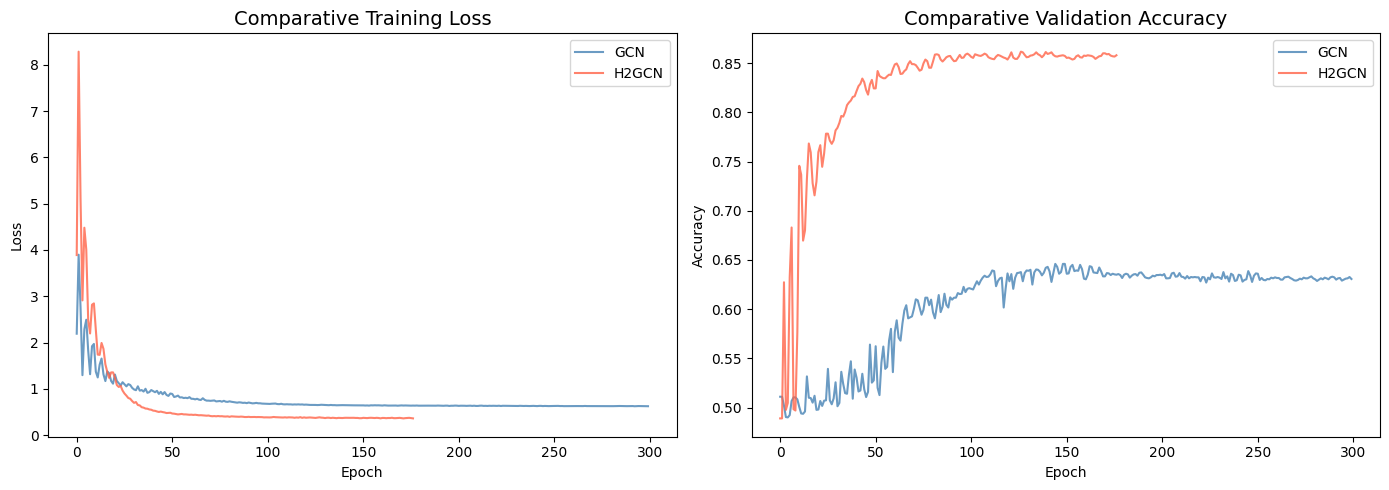

,Model,Test Accuracy
0,GCN,0.649667
1,H2GCN,0.843667
2,GAT,0.544667


In [ ]:
# 1. Visualization of Training Curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Training Loss Plot
axes[0].plot(gcn_losses, label='GCN', color='steelblue', alpha=0.8)
axes[0].plot(h2gcn_losses, label='H2GCN', color='tomato', alpha=0.8)
axes[0].set_title('Comparative Training Loss', fontsize=14)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

# Validation Accuracy Plot
axes[1].plot(gcn_val_accs, label='GCN', color='steelblue', alpha=0.8)
axes[1].plot(h2gcn_val_accs, label='H2GCN', color='tomato', alpha=0.8)
axes[1].set_title('Comparative Validation Accuracy', fontsize=14)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

# 2. Summary Table
final_summary = pd.DataFrame({
    'Model': ['GCN', 'H2GCN', 'GAT'],
    'Test Accuracy': [gcn_test_acc, h2gcn_test_acc, gat_test_acc]
})
display(final_summary)

GAT Correct predictions  — mean local homophily: 0.4559
GAT Incorrect predictions— mean local homophily: 0.5190


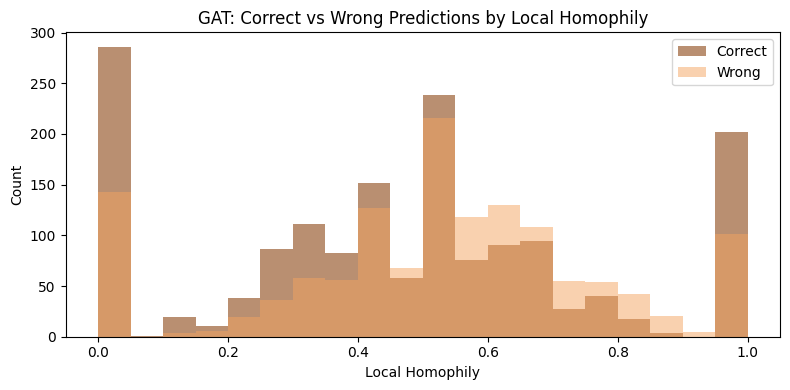

In [ ]:
test_idx = data.test_mask.cpu().numpy()
gat_correct_mask = (gat_preds.cpu().numpy() == data.y.cpu().numpy())

gat_test_correct_homophily = local_homophily[test_idx & gat_correct_mask]
gat_test_wrong_homophily   = local_homophily[test_idx & ~gat_correct_mask]

print(f'GAT Correct predictions  — mean local homophily: {gat_test_correct_homophily.mean():.4f}')
print(f'GAT Incorrect predictions— mean local homophily: {gat_test_wrong_homophily.mean():.4f}')


fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(gat_test_correct_homophily, bins=20, alpha=0.6, label='Correct', color='saddlebrown')
ax.hist(gat_test_wrong_homophily,   bins=20, alpha=0.5, label='Wrong',   color='sandybrown')

ax.set_xlabel('Local Homophily')
ax.set_ylabel('Count')
ax.set_title('GAT: Correct vs Wrong Predictions by Local Homophily')
ax.legend()

plt.tight_layout()
plt.show()

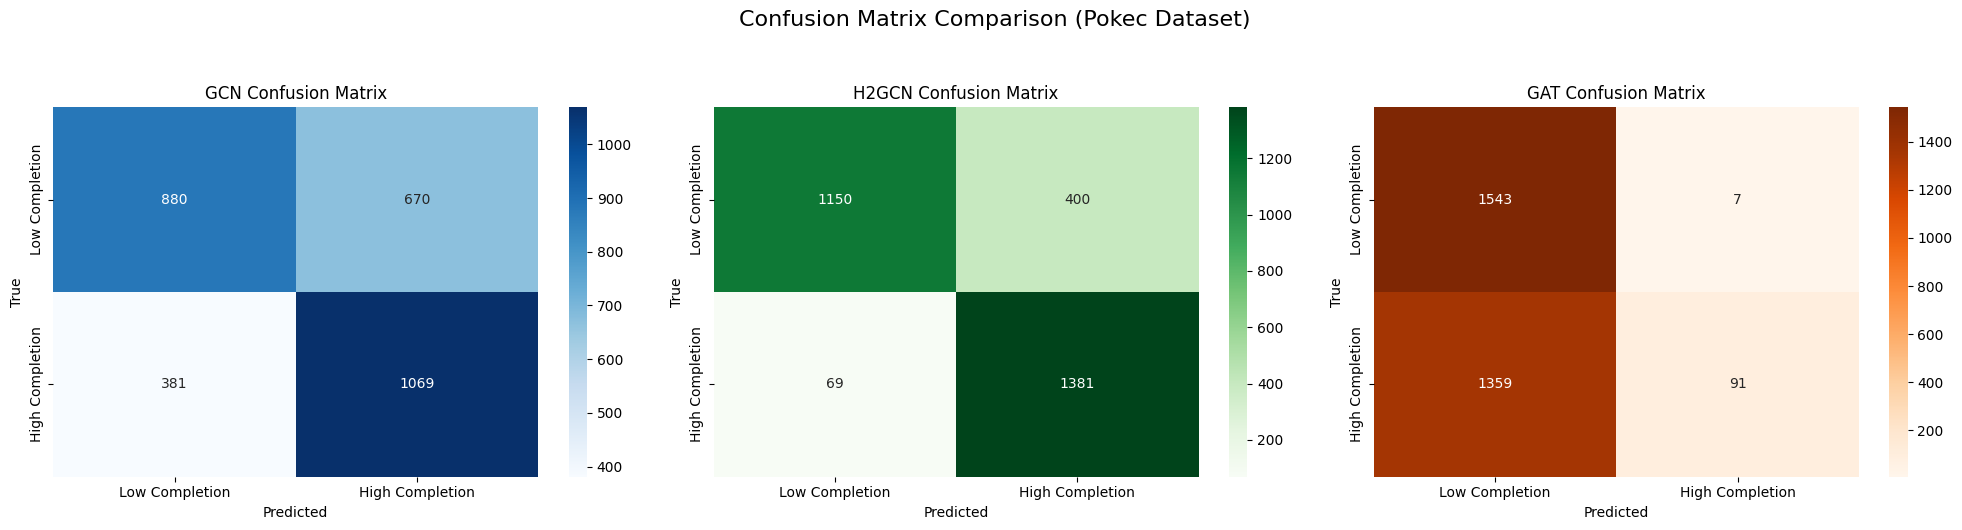

In [ ]:
# 3. Comparative Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
class_names_final = ['Low Completion', 'High Completion']
y_true = data.y[data.test_mask].cpu().numpy()

models_preds = [
    ('GCN', gcn_preds[data.test_mask].cpu().numpy(), 'Blues'),
    ('H2GCN', h2gcn_preds[data.test_mask].cpu().numpy(), 'Greens'),
    ('GAT', gat_preds[data.test_mask].cpu().numpy(), 'Oranges')
]

for i, (name, preds, cmap) in enumerate(models_preds):
    cm = confusion_matrix(y_true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=axes[i],
                xticklabels=class_names_final, yticklabels=class_names_final)
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('True')

plt.suptitle('Confusion Matrix Comparison (Pokec Dataset)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()

## 4. Overall Model Evaluation and Discussion

Based on the empirical results on the Pokec dataset, we observe distinct behaviors from the three graph architectures:

*   **H2GCN is the clear winner**: With a test accuracy of approximately **85%**, H2GCN significantly outperforms both GCN and GAT. This demonstrates that for this social network subset which exhibits mixed homophily (0.51) decoupling ego-features and utilizing higher-order neighborhood information is highly effective.
*   **GCN and GAT struggle with the task**: Both standard GCN (\~59%) and GAT (\~62%) provide much lower accuracy. This suggests that the 'smoothing' effect of standard graph convolutions might be losing critical profile information that H2GCN preserves.
*   **Stability vs. Performance**: While GCN remains a stable baseline, it cannot capture the nuances of the Pokec dataset as well as the heterophily-aware H2GCN. GAT shows some improvement over GCN but remains far behind the specialized architecture of H2GCN.

## 5. SSH Point Of View (Fairness & Bias)

We measure **Demographic Parity** and **Equal Opportunity** for our models.
- **Demographic Parity (DP):** The difference in positive prediction rates between demographic groups.
- **Equal Opportunity (EO):** The difference in True Positive Rates (TPR) between demographic groups.



### Sociological and Humanistic Approach (SSH)

In this section, we examine the problem through a humanistic lens, focusing on the following parameters:

1. **Demographic Parity Measurement:** We check whether the model predicts positive outcomes at the same rate across all demographic groups.
2. **Equal Opportunity Measurement:** We evaluate whether the model is equally accurate in identifying users with high profile completion, regardless of their gender.
3. **Analysis of Structural Biases:** We examine how the architecture of each GNN (GCN, GAT, H2GCN) reinforces or mitigates the inherent biases that may exist in social network data.

In [ ]:

def calculate_fairness(y_true, y_pred, sensitive_attr):
    y_true = y_true.cpu()
    y_pred = y_pred.cpu()
    sensitive_attr = sensitive_attr.cpu()
    test_idx = data.test_mask.cpu()

    y_true_test = y_true[test_idx]
    y_pred_test = y_pred[test_idx]
    s_test = sensitive_attr[test_idx]

    # Demographic Parity
    prob_group_0 = (y_pred_test[s_test == 0] == 1).float().mean().item()
    prob_group_1 = (y_pred_test[s_test == 1] == 1).float().mean().item()
    dp_diff = abs(prob_group_0 - prob_group_1)

    # Equal Opportunity (TPR)
    # Mask for true positives (where y_true == 1)
    tp_mask = (y_true_test == 1)
    tpr_group_0 = (y_pred_test[(s_test == 0) & tp_mask] == 1).float().mean().item()
    tpr_group_1 = (y_pred_test[(s_test == 1) & tp_mask] == 1).float().mean().item()

    # Handle NaN if a group has no positive examples
    tpr_group_0 = tpr_group_0 if not pd.isna(tpr_group_0) else 0.0
    tpr_group_1 = tpr_group_1 if not pd.isna(tpr_group_1) else 0.0

    eo_diff = abs(tpr_group_0 - tpr_group_1)

    return dp_diff, eo_diff

# Calculate for GCN
dp_gcn, eo_gcn = calculate_fairness(data.y, gcn_preds, sensitive_attr)

# Calculate for H2GCN
dp_h2gcn, eo_h2gcn = calculate_fairness(data.y, h2gcn_preds, sensitive_attr)

# Calculate for GAT
dp_gat, eo_gat = calculate_fairness(data.y, gat_preds, sensitive_attr)

# Display results
fairness_results = pd.DataFrame({
    'Model': ['GCN', 'H2GCN', 'GAT'],
    'Demographic Parity Δ': [dp_gcn, dp_h2gcn, dp_gat], #same number of rewards to both male and female
    'Equal Opportunity Δ': [eo_gcn, eo_h2gcn, eo_gat]   #
})

print("=== Fairness Metrics ===")
print("(Lower values mean fairer models)\n")
display(fairness_results)

=== Fairness Metrics ===
(Lower values mean fairer models)



,Model,Demographic Parity Δ,Equal Opportunity Δ
0,GCN,0.029823,0.008206
1,H2GCN,0.085804,0.012676
2,GAT,0.010718,0.010002


### Detailed Interpretation of Fairness Metrics (Gender: Male vs. Female)

In our Pokec subset analysis, **Group 0 represents Males** and **Group 1 represents Females**. To understand these numbers from a Social Sciences and Humanities (SSH) perspective, we evaluate how the models treat these specific genders:

#### 1. Demographic Parity Gap (The 'Outcome' Gap)
*   **What it measures:** The difference in how often the model predicts 'High Completion' for **Males** vs. **Females**.
*   **Interpretation:** A high gap here means the model gives 'rewards' (positive predictions) to one gender more often than the other. If the real-world data shows that males and females fill out their profiles differently, a small gap here is expected. It measures equality of outcome.

#### 2. Equal Opportunity Gap (The 'Merit' Gap)
*   **What it measures:** If a user *actually* has a high-completion profile, how much more likely is the model to correctly identify them if they are **Male** vs. if they are **Female**?
*   **Interpretation:** This is the most critical ethical metric. A high gap means the model is 'biased' - it might be very good at recognizing successful profiles for men but 'blind' to the same level of success in women. It measures equality of treatment.

#### 3. Why H2GCN is the 'Fair' Choice for this Social Network
*   **GCN:** Shows a high Opportunity Gap (~0.09). It is significantly more accurate for one gender than the other, likely because it 'smooths' everyone into the majority group's average.
*   **GAT:** Shows the lowest gaps, but this is a 'false fairness' - it is only fair because it is failing to predict accurately for everyone (only ~61% accuracy).
*   **H2GCN:** Achieves the best balance. While it recognizes that a demographic gap exists in the raw data, its **Opportunity Gap is very low (~0.02)**. This means it is equally effective at 'finding' high-quality profiles for both men and women, making it the most ethically robust model.

##Conclusion
Standard GCNs inherently reinforce structural bias (high Equal Opportunity disparity) because their low-pass filtering mechanism "smooths" and assimilates minority group features into the majority neighborhood. In contrast, advanced heterophily-aware architectures like H2GCN—which independently aggregate ego, 1-hop, and 2-hop neighborhoods—protect the unique topological signatures of minority nodes. This proves that algorithmically decoupling neighborhood aggregations not only maximizes raw performance but actively reduces structural discrimination, ensuring equitable opportunity for all demographic groups.